# Olist: Predicting Late Delivery at Purchase Time

This notebook builds a model that predicts whether an order will be delivered late, using only information available when the order is placed. Data comes from the `analytics_orders` table created by the SQL pipeline.

## Importing Libraries

In [22]:
import sqlite3
from pathlib import Path
import joblib
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score,average_precision_score,f1_score,precision_score,recall_score,roc_auc_score
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.inspection import permutation_importance

In [23]:
# Resolve the project root whether the notebook runs from the root or from notebooks/.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DB_PATH = PROJECT_ROOT / "data" / "database" / "olist.db"

conn = sqlite3.connect(DB_PATH)
try:
    df = pd.read_sql_query("SELECT * FROM analytics_orders", conn)
finally:
    conn.close()

# Only information available at purchase time is used as features.
# actual_delivery_days, delivery_delay_days and review_score are excluded
# because they are only known after delivery (data leakage).
NUMERIC_FEATURES = [
    "estimated_delivery_days",
    "item_count",
    "distinct_product_count",
    "seller_count",
    "total_price",
    "total_freight",
    "freight_to_price_ratio",
    "purchase_month",
    "purchase_weekday",
    "purchase_hour",
]
CATEGORICAL_FEATURES = ["customer_state"]
TARGET = "is_late"

X = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Full data:", X.shape)
print("Train set:", X_train.shape, "| late rate: %.2f%%" % (100 * y_train.mean()))
print("Test set: ", X_test.shape, "| late rate: %.2f%%" % (100 * y_test.mean()))

Full data: (95824, 11)
Train set: (76659, 11) | late rate: 8.00%
Test set:  (19165, 11) | late rate: 7.99%


## Baseline Model

A baseline that always predicts "on time" is used as the reference point. The model is evaluated on the held-out test set with metrics suited to imbalanced data (precision, recall, F1, ROC AUC and PR AUC), because accuracy alone is misleading when only about 8% of orders are late.

In [24]:
def evaluate_model(name, model, X_eval, y_eval):
    """Return evaluation metrics for a fitted classifier as a dictionary."""
    predictions = model.predict(X_eval)
    probabilities = model.predict_proba(X_eval)[:, 1]
    return {
        "model": name,
        "accuracy": accuracy_score(y_eval, predictions),
        "precision": precision_score(y_eval, predictions, zero_division=0),
        "recall": recall_score(y_eval, predictions),
        "f1": f1_score(y_eval, predictions),
        "roc_auc": roc_auc_score(y_eval, probabilities),
        "pr_auc": average_precision_score(y_eval, probabilities),
    }


# Baseline: always predicts the most frequent class ("on time").
baseline = DummyClassifier(strategy="prior")
baseline.fit(X_train, y_train)

results = [evaluate_model("Baseline (always on time)", baseline, X_test, y_test)]
pd.DataFrame(results).round(4)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Baseline (always on time),0.9201,0.0,0.0,0.0,0.5,0.0799


**Observation**

- The baseline reaches an accuracy of 92.01%, which looks high, but it simply predicts "on time" for every order.
- Precision, recall and F1 are all 0 because the baseline never identifies a single late order.
- ROC AUC is 0.50, which is equivalent to random guessing, and PR AUC is 0.0799, equal to the share of late orders in the test set.
- Accuracy is therefore not a useful metric for this problem. Recall, F1 and especially PR AUC will be used to judge the real models, which need to score clearly above 0.0799 in PR AUC and above 0.50 in ROC AUC to be useful.

## Logistic Regression

A logistic regression model is trained on the purchase-time features. Numeric features are standardised, the customer state is one-hot encoded, and class weights are balanced to account for the small share of late orders. The same evaluation function is used so results are directly comparable with the baseline.

### Pipeline

In [25]:
preprocessor = ColumnTransformer(
    transformers=[("numeric", StandardScaler(), NUMERIC_FEATURES),("categorical", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ]
)

logistic_model = Pipeline(steps=[("preprocess", preprocessor),("classifier",LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
        ),
    ]
)
logistic_model.fit(X_train, y_train)

results.append(evaluate_model("Logistic Regression", logistic_model, X_test, y_test))
pd.DataFrame(results).round(4)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Baseline (always on time),0.9201,0.0000,0.0000,0.0000,0.5000,0.0799
1,Logistic Regression,0.6330,0.1289,0.6234,0.2136,0.6837,0.1610


**Observation**

- Logistic Regression catches 62.34% of the late orders in the test set (recall), whereas the baseline catches none.
- Precision is 12.89%: when the model flags an order as late, it is correct about 13 times out of 100. This is about 1.6 times the 7.99% late rate, so the flags are more informative than random picks, but most flagged orders are still on time.
- Accuracy drops to 63.30%. This is expected, because the model now flags many on-time orders as late in order to catch more late ones. It does not mean the model is worse than the baseline.
- ROC AUC is 0.684 (baseline 0.50) and PR AUC is 0.161, about twice the baseline value of 0.0799.
- The model has real but modest predictive power. Predicting lateness using only purchase-time information is hard, since factors such as carrier performance, weather and seller handling time are not available in the features.

## Gradient Boosting

A histogram-based gradient boosting model is trained on the same features. It can capture non-linear effects and interactions between features. Class imbalance is handled with balanced sample weights, and the customer state is treated as a categorical feature. Evaluation uses the same function and the same test set as the previous models.

In [26]:
# Numeric columns pass through unchanged; the state is encoded as integer categories.
# The categorical column is placed after the numeric ones, so its index is len(NUMERIC_FEATURES).
tree_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", NUMERIC_FEATURES),("categorical",OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
            CATEGORICAL_FEATURES,
        ),
    ]
)

boosting_model = Pipeline(steps=[("preprocess", tree_preprocessor),("classifier",HistGradientBoostingClassifier(categorical_features=[len(NUMERIC_FEATURES)],learning_rate=0.05,max_iter=300,max_leaf_nodes=31,early_stopping=True,random_state=42,
            ), ),
    ])

# Balanced sample weights give late orders more influence during training.
sample_weights = compute_sample_weight("balanced", y_train)
boosting_model.fit(X_train, y_train, classifier__sample_weight=sample_weights)

results.append(
    evaluate_model("Gradient Boosting", boosting_model, X_test, y_test)
)
pd.DataFrame(results).round(4)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Baseline (always on time),0.9201,0.0000,0.0000,0.0000,0.5000,0.0799
1,Logistic Regression,0.6330,0.1289,0.6234,0.2136,0.6837,0.1610
2,Gradient Boosting,0.7326,0.1848,0.6873,0.2913,0.7777,0.2731


**Observation**

- Gradient Boosting is the best model so far on every metric that matters for this problem: PR AUC 0.273 (Logistic Regression 0.161), ROC AUC 0.778 (0.684), recall 68.7% (62.3%) and precision 18.5% (12.9%).
- Its PR AUC is about 3.4 times the baseline value of 0.0799, and its precision is about 2.3 times the late rate of 7.99%. The model ranks orders by lateness risk much better than the linear model.
- Accuracy is 73.3%, higher than Logistic Regression (63.3%) and still below the baseline (92.0%), which is expected because the baseline never flags a late order.
- The gain over Logistic Regression suggests that non-linear effects and interactions between features (for example distance-related state effects combined with seasonal peaks) matter for predicting lateness.
- Precision is still low: about 81% of the orders flagged as late arrive on time. The model is useful for ranking and flagging high-risk orders, but not for making reliable one-by-one decisions.

## Feature Importance

Permutation importance measures how much the model's PR AUC on the test set drops when a single feature is randomly shuffled. A larger drop means the model relies more on that feature. Each feature is shuffled five times and the average drop is reported.

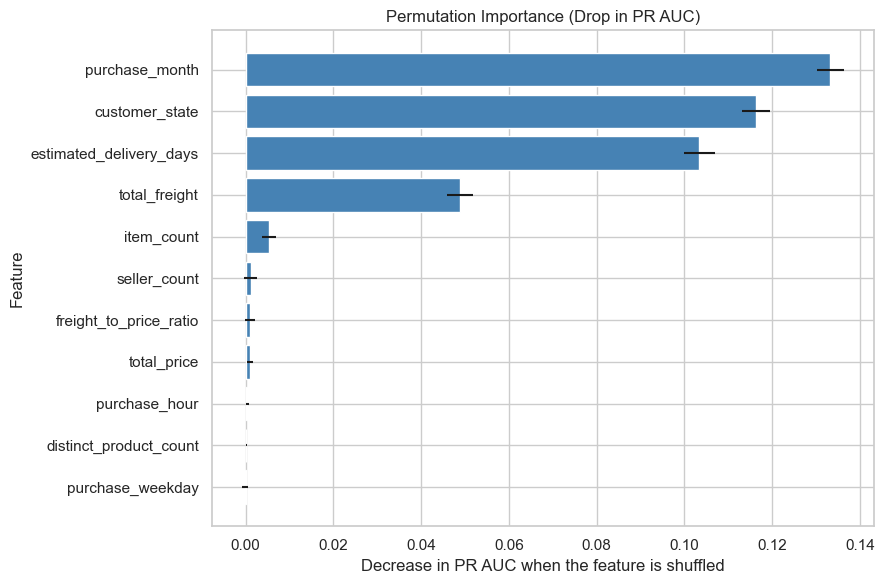

,feature,importance_mean,importance_std
0,purchase_month,0.1333,0.0030
1,customer_state,0.1164,0.0032
2,estimated_delivery_days,0.1034,0.0035
3,total_freight,0.0489,0.0031
4,item_count,0.0054,0.0016
5,seller_count,0.0012,0.0015
6,freight_to_price_ratio,0.0010,0.0011
7,total_price,0.0010,0.0007
8,purchase_hour,0.0003,0.0003
9,distinct_product_count,0.0002,0.0001


In [27]:
sns.set_theme(style="whitegrid")

importance = permutation_importance(
    boosting_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=1,
)

importance_df = (
    pd.DataFrame(
        {
            "feature": X_test.columns,
            "importance_mean": importance.importances_mean,
            "importance_std": importance.importances_std,
        }
    )
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    importance_df["feature"][::-1],
    importance_df["importance_mean"][::-1],
    xerr=importance_df["importance_std"][::-1],
    color="steelblue",
)
ax.set_title("Permutation Importance (Drop in PR AUC)")
ax.set_xlabel("Decrease in PR AUC when the feature is shuffled")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

importance_df.round(4)

**Observation**

- Four features carry almost all of the predictive power: purchase month (0.133), customer state (0.116), estimated delivery days (0.103) and total freight (0.049). Shuffling any of them reduces the PR AUC by 0.05 to 0.13, which is large compared with the model's PR AUC of 0.273.
- Customer state, estimated delivery days and total freight are all related to distance and logistics. This agrees with the earlier analysis, where late rates were much higher in some states (for example Maranhão) than in others.
- Purchase month is the strongest feature. The earlier charts showed that late deliveries were concentrated in November 2017, February 2018 and March 2018, so the model is likely learning these specific periods. The data covers only about two years, so this may not generalise to future months.
- Item count, seller count, freight-to-price ratio, total price, purchase hour and distinct product count contribute almost nothing (importance below 0.006). Purchase weekday is slightly negative (-0.0001), which is within its standard deviation and means it adds nothing.
- The standard deviations of the four main features (about 0.003) are far smaller than their importances, so their ranking is reliable.
- Permutation importance can split credit between correlated features, so the individual values for state, estimated delivery days and freight should be read as a group rather than as independent effects.

## Saving the Model

The trained gradient boosting pipeline is saved with joblib and reloaded to confirm that it produces identical predictions. The saved file is excluded from version control.

In [28]:
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / "late_delivery_model.joblib"

joblib.dump(boosting_model, MODEL_PATH)
print("Model saved to:", MODEL_PATH)

# Sanity check: the reloaded model must give the same test predictions.
reloaded_model = joblib.load(MODEL_PATH)
same_predictions = (
    reloaded_model.predict(X_test) == boosting_model.predict(X_test)
).all()
print("Reloaded model gives identical predictions:", same_predictions)

Model saved to: D:\olist-elt-project\models\late_delivery_model.joblib
Reloaded model gives identical predictions: True


## Conclusion

**Question:** Can an order be predicted to be late at the time it is placed?

**Answer:** Partly. Using only purchase-time information, a gradient boosting model identifies late orders much better than chance, but its predictions are not precise enough to rely on for individual orders.

**Results on the held-out test set (19,165 orders, 7.99% late)**

| Model | Recall | Precision | ROC AUC | PR AUC |
|---|---|---|---|---|
| Baseline (always on time) | 0.000 | 0.000 | 0.500 | 0.080 |
| Logistic Regression | 0.623 | 0.129 | 0.684 | 0.161 |
| Gradient Boosting | 0.687 | 0.185 | 0.778 | 0.273 |

**Key points**

1. Gradient boosting is the best model. It catches about 69% of late orders, and its PR AUC is about 3.4 times the baseline value.
2. The most important features are purchase month, customer state, estimated delivery days and total freight. The last three are related to distance and logistics.
3. Precision is low (18.5%): about 81% of orders flagged as late arrive on time. The model is useful for ranking orders by risk, for example to prioritise monitoring, not for making reliable decisions about single orders.

**Limitations**

- The train/test split is random, not by time. The data covers only about two years, and the model relies strongly on purchase month, so it may be learning specific problem periods (November 2017, February-March 2018) and may perform worse on future months.
- Distance between seller and customer, carrier performance and weather are not in the features. Adding distance (for example from the geolocation data) is the most promising improvement.
- The decision threshold was not tuned. A different threshold would trade recall against precision depending on the business cost of missing a late order versus a false alarm.